In [5]:
import pandas as pd
import sqlite3

conn = sqlite3.connect(r'D:\quant_learning\week4_sql\window_practice.db')
stocks = pd.read_sql('SELECT * FROM stocks', conn)
print(stocks.shape)
print(stocks.head())

(10, 3)
     code industry   mktcap
0  600519       白酒  18800.0
1  000858       白酒   5800.0
2  601398       银行  16000.0
3  600036       银行   8800.0
4  000001       银行   2300.0


In [ ]:
agg = pd.read_sql(
    '''
    SELECT industry,
    COUNT(*) AS n,
    ROUND(AVG(mktcap),1) AS avg_cap
    FROM stocks
    GROUP BY industry
    ORDER BY avg_cap DESC
    ''',conn)
print(agg)

  industry  n  avg_cap
0       白酒  2  12300.0
1       银行  3   9033.3
2       电池  2   8250.0
3       医药  3   2966.7


In [14]:
ma = pd.read_sql(
    '''
    SELECT code, trade_date, close,
        AVG(close) OVER(
                PARTITION BY code ORDER BY trade_date
                ROWS BETWEEN 4 PRECEDING AND CURRENT ROW
        ) AS ma5
    FROM prices
    ''', conn)

ma['trade_date'] = pd.to_datetime(ma['trade_date'])
print(ma.shape)
print(ma.tail())

(16, 4)
      code trade_date   close     ma5
11  600519 2024-01-05  1710.0  1702.5
12  600519 2024-01-08  1750.0  1712.0
13  600519 2024-01-09  1730.0  1718.0
14  600519 2024-01-10  1760.0  1734.0
15  600519 2024-01-11  1780.0  1746.0


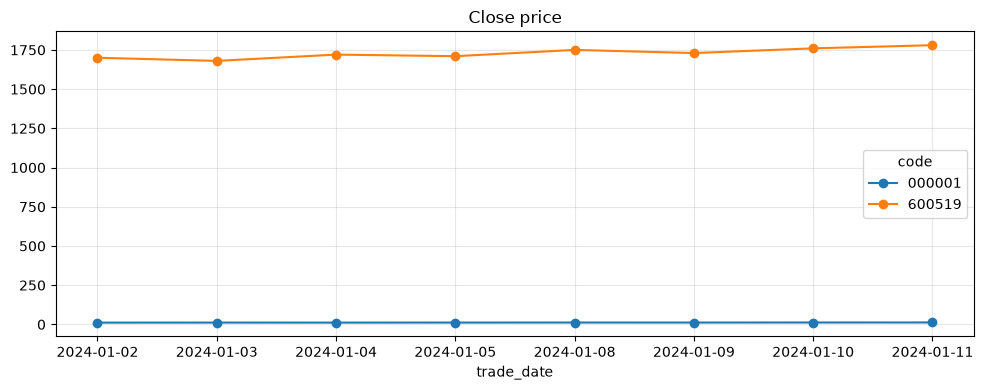

<function Connection.close()>

In [20]:
import matplotlib.pyplot as plt

prices = pd.read_sql('SELECT * FROM prices', conn)
wide = prices.pivot(index='trade_date', columns='code', values='close')

fig, ax = plt.subplots(figsize=(10,4))
wide.plot(ax=ax,marker='o')
ax.set_title('Close price')
ax.set_xlabel('trade_date')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(r'D:\quant_learning\week4_sql\read_sql_bridge.png',dpi=120)
plt.show()
conn.close